# Probabilistic FDM — 非線形楕円型 PDE (Chen et al. 2021 と同じ設定)

PDE: $-\Delta u + u^3 = f$, $(x,y) \in (0,1)^2$, $u=0$ on $\partial(0,1)^2$

prescribed solution: $u^*(x,y) = \sin(\pi x)\sin(\pi y) + 4\sin(4\pi x)\sin(4\pi y)$

観測モデル: $f = \mathcal{F}(u) + \epsilon$, $\mathcal{F}(u) = D_h u + u^3$ (非線形！)

Laplace 近似:
1. MAP 推定: $\hat{u} = \arg\min [\|u\|^2_{K^{-1}} + \|\mathcal{F}(u) - f\|^2_{\Sigma^{-1}}]$ (Newton 法)
2. 事後分散: $\Sigma^{\text{post}} = K - KJ^\top(JKJ^\top + \Sigma)^{-1}JK$ (Jacobian で線形化)

**Chen et al. (2021) との違い: 同じ PDE・prescribed solution を使用するが，提案手法はさらに事後分散による UQ を提供する。**


In [1]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics
using SparseArrays
using Printf
println("Packages loaded.")


Packages loaded.


In [2]:
# 1次元 Matérnカーネル
function matern_kernel_1d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_1d(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = length(X1), length(X2)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_1d(X1[i], X2[j]; ν=ν, ℓ=ℓ, σf=σf)
    end
    return K
end
println("1D Kernel defined.")


1D Kernel defined.


In [3]:
# ============================================================
# グリッド設定 + 解析解
# ============================================================
function make_grid_1d(Nx)
    dx = 1.0 / (Nx + 1)
    x  = [dx*i for i in 1:Nx]
    return dx, x, Nx
end

# prescribed solution: u*(x) = sin(pi*x) + 0.5*sin(4*pi*x)
u_true(x)   = sin(pi*x) + 0.5*sin(4*pi*x)
neg_lap_u(x) = pi^2*sin(pi*x) + 0.5*(4*pi)^2*sin(4*pi*x)
f_rhs(x)    = neg_lap_u(x) + u_true(x)^3

println("Grid and analytical solution defined.")


Grid and analytical solution defined.


In [4]:
# ============================================================
# 情報作用素 D_h = -Delta_h (線形, 三対角行列)
# ============================================================
function make_Dh_1d(Nx, dx)
    D = zeros(Nx, Nx)
    for i in 1:Nx
        D[i,i] = 2.0/dx^2
        i > 1  && (D[i,i-1] = -1.0/dx^2)
        i < Nx && (D[i,i+1] = -1.0/dx^2)
    end
    return D
end

# 非線形情報作用素: F(u) = D_h*u + u^3
function nonlinear_F(u, Dh)
    return Dh*u + u.^3
end

# Jacobian: J(u) = D_h + diag(3*u^2)
function jacobian_F(u, Dh)
    return Dh + Diagonal(3*u.^2)
end

println("Dh and nonlinear operators defined.")


Dh and nonlinear operators defined.


In [10]:
# ============================================================
# 通常の FDM 解 (Newton 法, prior なし)
# ============================================================
function newton_fdm(dx, Nx, f_vals; tol=1e-10, maxiter=100)
    Dh = make_Dh_1d(Nx, dx)
    u  = zeros(Nx)
    for it in 1:maxiter
        F  = nonlinear_F(u, Dh) - f_vals
        J  = jacobian_F(u, Dh)
        du = J \ (-F)
        u .+= du
        if norm(du) < tol
            println("  FDM Newton converged at iter $(it)")
            break
        end
    end
    return u
end

# MAP推定のNewton法
function newton_map(dx, Nx, f_vals, K; C=1.0, tau=2, tol=1e-10, maxiter=100)
    Dh        = make_Dh_1d(Nx, dx)
    u         = zeros(Nx)
    noise_var = C * dx^(2*tau)
    Sigma_inv = (1.0/noise_var) * I
    K_inv     = inv(Matrix(K) + 1e-8*I)
    for it in 1:maxiter
        F_val = nonlinear_F(u, Dh) - f_vals
        J     = jacobian_F(u, Dh)
        H     = J' * Sigma_inv * J + K_inv
        g     = J' * Sigma_inv * F_val + K_inv * u
        du    = H \ (-g)
        u .+= du
        if norm(du) < tol
            #println("  MAP Newton converged at iter $(it)")
            break
        end
    end
    return u
end

println("Newton functions defined.")


Newton functions defined.


In [11]:
# ============================================================
# Laplace 近似
# 事後平均: mu_post = u_map
# 事後分散: Sigma_post = K - K J^T (J K J^T + Sigma)^{-1} J K
# ============================================================
function laplace_posterior(u_map, dx, Nx, K; C=1.0, tau=2)
    Dh          = make_Dh_1d(Nx, dx)
    J           = jacobian_F(u_map, Dh)
    noise_var   = C * dx^(2*tau)
    Sigma_noise = noise_var * I

    JK       = J * K
    M        = Symmetric(JK * J' + Sigma_noise + 1e-10*I)
    L        = cholesky(M).L

    mu_post  = u_map
    V        = L \ JK
    Sig_post = K - V' * V
    std_post = sqrt.(max.(diag(Sig_post), 0.0))

    return mu_post, std_post
end

println("laplace_posterior defined.")


laplace_posterior defined.


In [12]:
# ============================================================
# Grid search (σf固定, ℓとCをgrid search)
# 各候補でMAP推定 → marginal likelihood を表で表示
# ============================================================

function log_mll_1d(u_map, dx, Nx, K; C=1.0, tau=2)
    Dh          = make_Dh_1d(Nx, dx)
    J           = jacobian_F(u_map, Dh)
    noise_var   = C * dx^(2*tau)
    Sigma_noise = noise_var * I
    JK = J * K
    M  = Symmetric(JK * J' + Sigma_noise + 1e-10*I)
    try
        L = cholesky(M).L
        return -sum(log.(diag(L)))
    catch
        return -Inf
    end
end

function grid_search_1d(u_fdm, f_vals, x_all, dx, Nx;
                         tau=2, nu_ker=1.5, σf_fixed=0.5)
    ℓ_grid = 10.0 .^ range(-2, 1, length=8)
    C_grid = 10.0 .^ range(-3, 2, length=8)

    best_lml = -Inf
    best_l   = 0.5
    best_C   = 1.0

    println("\n=== Marginal likelihood table (σf=$(σf_fixed) fixed) ===")
    @printf("%-12s", "l \\ C")
    for C in C_grid
        @printf("%-11s", "$(round(C,sigdigits=2))")
    end
    println()
    println("-"^(12 + 11*length(C_grid)))

    for l in ℓ_grid
        @printf("%-12s", "$(round(l,sigdigits=2))")
        for C in C_grid
            K_cand = Symmetric(kernel_matrix_1d(x_all, x_all; ν=nu_ker, ℓ=l, σf=σf_fixed) + 1e-8*I)
            u_map_cand = newton_map(dx, Nx, f_vals, K_cand; C=C, tau=tau)
            lml = log_mll_1d(u_map_cand, dx, Nx, K_cand; C=C, tau=tau)
            @printf("%-11s", round(lml, digits=1))
            if lml > best_lml
                best_lml = lml
                best_l   = l
                best_C   = C
            end
        end
        println()
    end
    println("-"^(12 + 11*length(C_grid)))
    println("Best: ℓ=$(round(best_l,digits=4)), C=$(round(best_C,digits=4)), lml=$(round(best_lml,digits=2))")
    return σf_fixed, best_l, best_C, best_lml
end

println("Grid search defined.")


Grid search defined.


In [17]:
# ============================================================
# 設定
# ============================================================
Nx     = 20
nu_ker = 1.5
tau_fixed = 2

dx, x_all, N = make_grid_1d(Nx)
println("Nx=$(Nx), N=$(N), dx=$(round(dx,digits=4))")

u_star = u_true.(x_all)
f_vals = f_rhs.(x_all)

println("max(u_star) = $(round(maximum(abs.(u_star)), digits=4))")
println("max(f_vals) = $(round(maximum(abs.(f_vals)), digits=4))")

# 通常のFDM解
println("\nRunning FDM Newton...")
u_fdm = newton_fdm(dx, Nx, f_vals)
err_fdm = maximum(abs.(u_fdm - u_star))
println("FDM L∞ error = $(round(err_fdm, digits=6))")
println("Expected O(h^2) = $(round(dx^2, digits=6))")

# yのスケール確認
Dh_check = make_Dh_1d(Nx, dx)
J_check  = jacobian_F(u_fdm, Dh_check)
println("\n=== スケール確認 ===")
println("norm(J*u_fdm) = $(round(norm(J_check*u_fdm), digits=4))  ← y のスケール")
println("dx^(2*tau)    = $(round(dx^(2*tau_fixed), digits=8))       ← noise のスケール")
println("ratio         = $(round(norm(J_check*u_fdm)^2 / dx^(2*tau_fixed), digits=1))")


Nx=20, N=20, dx=0.0476
max(u_star) = 1.4295
max(f_vals) = 90.8444

Running FDM Newton...
  FDM Newton converged at iter 5
FDM L∞ error = 0.015089
Expected O(h^2) = 0.002268

=== スケール確認 ===
norm(J*u_fdm) = 267.8098  ← y のスケール
dx^(2*tau)    = 5.14e-6       ← noise のスケール
ratio         = 1.39485845104e10


In [18]:
# ============================================================
# Grid search → MAP 推定 → Laplace 近似
# ============================================================

σf_fixed = maximum(abs.(u_fdm))  # 解の振幅から推定
println("σf_fixed = $(round(σf_fixed, digits=4))")

best_sf, best_l, best_C, best_lml = grid_search_1d(
    u_fdm, f_vals, x_all, dx, Nx;
    tau=tau_fixed, nu_ker=nu_ker, σf_fixed=σf_fixed
)

# 最良のhyperparameterでGP prior
K_prior = Symmetric(kernel_matrix_1d(x_all, x_all; ν=nu_ker, ℓ=best_l, σf=best_sf) + 1e-8*I)

# 最終MAP推定
println("\nRunning final MAP Newton...")
u_map = newton_map(dx, Nx, f_vals, K_prior; C=best_C, tau=tau_fixed)
err_map = maximum(abs.(u_map - u_star))
println("MAP L∞ error = $(round(err_map, digits=6))")
println("FDM L∞ error = $(round(err_fdm, digits=6))")

# Laplace近似
mu_post, std_post = laplace_posterior(u_map, dx, Nx, K_prior; C=best_C, tau=tau_fixed)
println("max std      = $(round(maximum(std_post), digits=6))")


σf_fixed = 1.4439

=== Marginal likelihood table (σf=1.4438689992240057 fixed) ===
l \ C       0.001      0.0052     0.027      0.14       0.72       3.7        19.0       100.0      
----------------------------------------------------------------------------------------------------
0.01        -132.5     -132.5     -132.5     -132.5     -132.5     -132.5     -132.5     -132.5     
0.027       -132.2     -132.2     -132.2     -132.2     -132.2     -132.2     -132.2     -132.2     
0.072       -126.0     -126.0     -126.0     -126.0     -126.0     -126.0     -126.0     -126.0     
0.19        -109.4     -109.4     -109.4     -109.4     -109.4     -109.4     -109.4     -109.4     
0.52        -86.4      -86.4      -86.4      -86.4      -86.4      -86.4      -86.4      -86.4      
1.4         -60.6      -60.6      -60.6      -60.6      -60.6      -60.6      -60.6      -60.6      
3.7         -33.7      -33.7      -33.7      -33.7      -33.7      -33.7      -33.7      -33.7      
10.0    

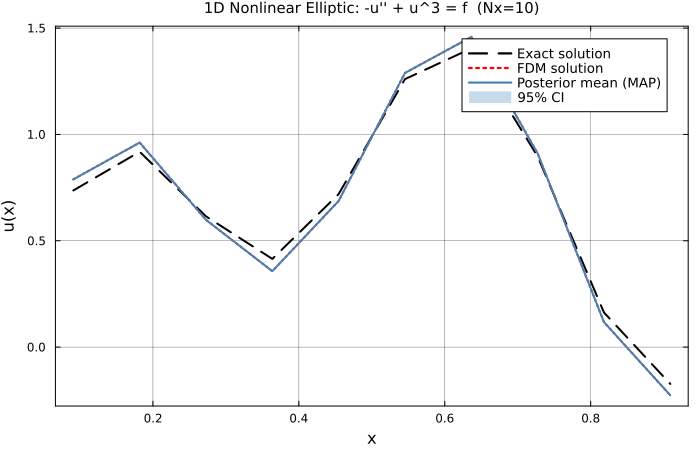

Saved!

Errors:
  FDM: 0.057687
  MAP: 0.057687
  max std: 9.0e-6


In [15]:
# ============================================================
# 可視化
# ============================================================
p = plot(x_all, u_star;
    label="Exact solution", lw=2, ls=:dash, color=:black,
    xlabel="x", ylabel="u(x)",
    title="1D Nonlinear Elliptic: -u'' + u^3 = f  (Nx=$(Nx))",
    titlefontsize=10, legendfontsize=9,
    grid=true, gridalpha=0.3, framestyle=:box, size=(700,450))
plot!(p, x_all, u_fdm;
    label="FDM solution", lw=2, ls=:dot, color=:red)
plot!(p, x_all, mu_post;
    label="Posterior mean (MAP)", lw=2, color=:steelblue)
plot!(p, x_all, mu_post .+ 1.96 .* std_post;
    lw=0, fillalpha=0, label=false, color=:steelblue)
plot!(p, x_all, mu_post .- 1.96 .* std_post;
    lw=0, fillrange=mu_post .+ 1.96 .* std_post,
    fillalpha=0.3, linealpha=0, label="95% CI", color=:steelblue)
display(p)
savefig(p, "nonlinear_elliptic_1d.png")
println("Saved!")

println("\nErrors:")
println("  FDM: $(round(maximum(abs.(u_fdm   - u_star)), digits=6))")
println("  MAP: $(round(maximum(abs.(mu_post  - u_star)), digits=6))")
println("  max std: $(round(maximum(std_post), digits=6))")


  FDM Newton converged at iter 5

=== Marginal likelihood table (σf=1.477570229043262 fixed) ===
l \ C       0.001      0.0052     0.027      0.14       0.72       3.7        19.0       100.0      
----------------------------------------------------------------------------------------------------
0.01        -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      
0.027       -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      
0.072       -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      -22.1      
0.19        -21.3      -21.3      -21.3      -21.3      -21.3      -21.3      -21.3      -21.3      
0.52        -18.5      -18.5      -18.5      -18.5      -18.5      -18.5      -18.5      -18.5      
1.4         -14.1      -14.1      -14.1      -14.1      -14.1      -14.1      -14.1      -14.1      
3.7         -9.1       -9.1       -9.1       -9.1       -9.1       -9.1       -9.1       -9.2  

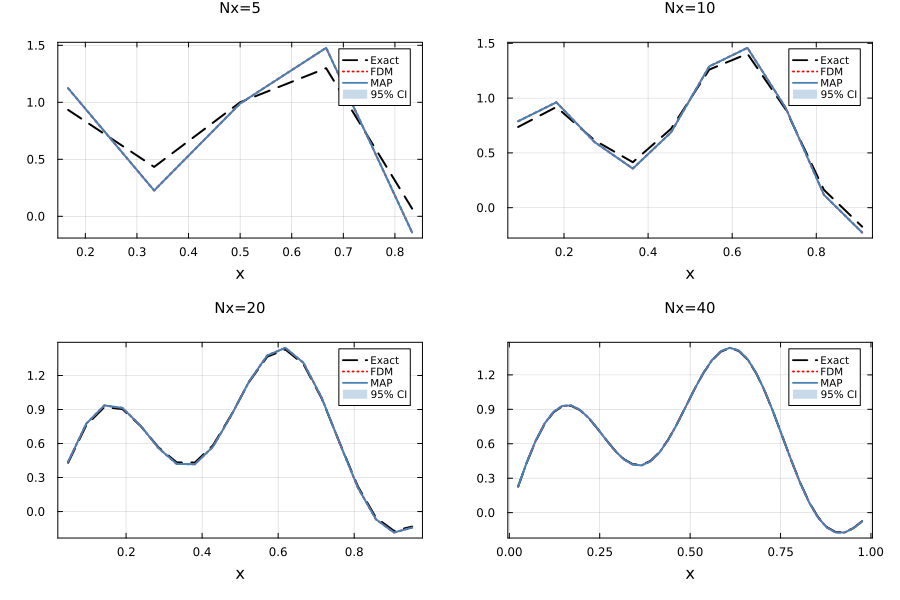

In [16]:
# ============================================================
# Nx sweep
# ============================================================
Nx_list = [5, 10, 20, 40]
plots_sweep = []

for nx in Nx_list
    dxx, xa, Nn = make_grid_1d(nx)
    u_st = u_true.(xa)
    f_vl = f_rhs.(xa)
    u_fd = newton_fdm(dxx, nx, f_vl)

    sf_fix = maximum(abs.(u_fd))
    sf, bl, bc, _ = grid_search_1d(u_fd, f_vl, xa, dxx, nx;
                                     tau=tau_fixed, nu_ker=nu_ker, σf_fixed=sf_fix)
    Kp  = Symmetric(kernel_matrix_1d(xa, xa; ν=nu_ker, ℓ=bl, σf=sf) + 1e-8*I)
    u_m = newton_map(dxx, nx, f_vl, Kp; C=bc, tau=tau_fixed)
    mu_p, std_p = laplace_posterior(u_m, dxx, nx, Kp; C=bc, tau=tau_fixed)

    err_fd  = round(maximum(abs.(u_fd - u_st)), digits=5)
    err_map = round(maximum(abs.(mu_p - u_st)), digits=5)
    println("Nx=$(nx): FDM=$(err_fd), MAP=$(err_map), max_std=$(round(maximum(std_p),digits=5))")

    pp = plot(xa, u_st; label="Exact", lw=2, ls=:dash, color=:black,
              xlabel="x", title="Nx=$(nx)", titlefontsize=10,
              legendfontsize=7, grid=true, framestyle=:box)
    plot!(pp, xa, u_fd;  label="FDM",  lw=2, ls=:dot,  color=:red)
    plot!(pp, xa, mu_p;  label="MAP",  lw=2, color=:steelblue)
    plot!(pp, xa, mu_p .+ 1.96.*std_p; lw=0, fillalpha=0, label=false, color=:steelblue)
    plot!(pp, xa, mu_p .- 1.96.*std_p; lw=0,
          fillrange=mu_p .+ 1.96.*std_p, fillalpha=0.3, linealpha=0,
          label="95% CI", color=:steelblue)
    push!(plots_sweep, pp)
end

fig_sweep = plot(plots_sweep...; layout=(2,2), size=(900,600), margin=5*Plots.mm)
display(fig_sweep)
savefig(fig_sweep, "nonlinear_elliptic_1d_sweep.png")
println("Saved!")
